In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [6]:
X, y_true = make_blobs(n_samples=500, centers=4, cluster_std=0.60, random_state=42)

In [7]:
df = pd.DataFrame(X, columns=['Feature 1', 'Feature 2'])

In [8]:
X

array([[-8.14876376,  6.90161706],
       [-8.49775918, -6.91268651],
       [ 5.9537606 ,  1.48819071],
       [-2.74446251,  8.13617716],
       [-6.15889884, -7.12495482],
       [-6.3814257 , -7.39375989],
       [-7.30227703,  7.26588698],
       [-6.7173531 , -6.91025246],
       [ 3.99930658,  1.88774199],
       [-7.25451834, -6.86445496],
       [ 4.25193511,  1.32424088],
       [-1.81404028,  8.52187674],
       [ 5.91969886,  0.801917  ],
       [-2.16666332,  9.69562551],
       [-6.70576228, -5.63486911],
       [ 5.27493353,  0.91792599],
       [-2.5524037 ,  9.61640587],
       [-9.51196097,  7.55296876],
       [-8.78895736,  7.96281114],
       [-3.17299861,  8.29656215],
       [ 3.80073829,  2.31095123],
       [-2.38387947,  7.83848405],
       [ 4.98581301,  2.15991978],
       [-7.89901334,  7.28407276],
       [-9.10618793,  7.43997691],
       [-6.64295591, -7.13270028],
       [-7.03261352, -5.9777138 ],
       [-8.36684766,  7.57879745],
       [-8.6780976 ,

In [9]:
df

,Feature 1,Feature 2
0,-8.148764,6.901617
1,-8.497759,-6.912687
2,5.953761,1.488191
3,-2.744463,8.136177
4,-6.158899,-7.124955
...,...,...
495,-7.998714,7.878303
496,-2.555459,9.218977
497,-7.081098,-5.878697
498,-7.193261,-6.250704


In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [11]:
inertia_values = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

In [12]:
inertia_values

[999.9999999999995,
 546.5846235701696,
 102.86282066086986,
 10.60225710567248,
 9.788532453328465,
 8.609530283250393,
 7.643455056196117,
 6.609413246919946,
 6.211509253893231,
 5.669352232274705]

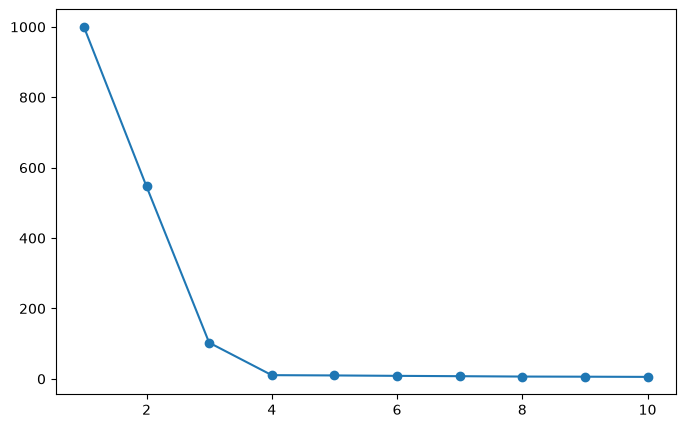

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia_values, marker='o')

In [14]:
k_means = KMeans(n_clusters=4, random_state=42)

In [15]:
cluster_labels = k_means.fit_predict(X_scaled)

In [16]:
cluster_labels

array([1, 2, 0, 3, 2, 2, 1, 2, 0, 2, 0, 3, 0, 3, 2, 0, 3, 1, 1, 3, 0, 3,
       0, 1, 1, 2, 2, 1, 1, 3, 2, 3, 3, 3, 2, 2, 0, 0, 1, 1, 2, 0, 3, 3,
       3, 0, 0, 0, 2, 1, 2, 3, 1, 2, 0, 3, 3, 1, 2, 1, 1, 3, 2, 1, 0, 2,
       2, 1, 0, 2, 0, 2, 2, 1, 3, 1, 3, 2, 0, 3, 2, 0, 2, 3, 1, 1, 1, 1,
       0, 3, 1, 2, 0, 2, 0, 1, 3, 0, 3, 1, 0, 0, 0, 1, 1, 3, 3, 1, 3, 1,
       2, 1, 1, 1, 1, 2, 0, 1, 2, 2, 3, 0, 2, 0, 1, 0, 0, 2, 2, 1, 1, 0,
       0, 2, 0, 1, 1, 1, 0, 0, 2, 1, 0, 0, 2, 1, 1, 3, 3, 3, 2, 2, 0, 0,
       3, 1, 3, 1, 2, 2, 1, 1, 0, 0, 2, 3, 0, 2, 1, 1, 2, 3, 3, 1, 1, 3,
       3, 2, 2, 2, 3, 1, 3, 3, 1, 1, 3, 0, 3, 2, 2, 1, 1, 2, 3, 2, 3, 3,
       1, 2, 3, 3, 2, 1, 0, 1, 2, 0, 0, 1, 1, 2, 1, 3, 3, 2, 3, 1, 3, 0,
       0, 3, 1, 3, 0, 3, 3, 2, 2, 0, 2, 0, 3, 2, 1, 2, 3, 2, 0, 0, 0, 2,
       3, 0, 1, 1, 0, 3, 3, 2, 3, 3, 3, 3, 0, 0, 1, 3, 2, 0, 3, 3, 1, 3,
       2, 2, 0, 3, 0, 2, 3, 3, 0, 1, 3, 3, 3, 0, 1, 2, 3, 0, 0, 3, 2, 3,
       0, 1, 0, 2, 2, 3, 3, 0, 1, 0, 1, 0, 2, 0, 2,

In [17]:
df['cluster'] = cluster_labels

<Axes: xlabel='Feature 1', ylabel='Feature 2'>

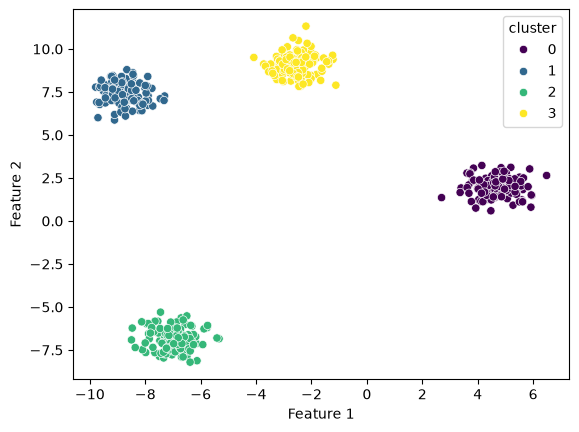

In [18]:
sns.scatterplot(data=df, x='Feature 1', y='Feature 2', hue='cluster', palette='viridis')

# DBSCAN

In [19]:
from sklearn.datasets import make_moons

In [20]:
X, y_true = make_moons(n_samples=500, noise=0.05, random_state=42)

In [21]:
from sklearn.cluster import KMeans,DBSCAN

In [22]:
df = pd.DataFrame(X, columns=['Feature 1', 'Feature 2'])

In [23]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [24]:
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

In [26]:
df['kmeans_labels'] = kmeans_labels

<Axes: xlabel='Feature 1', ylabel='Feature 2'>

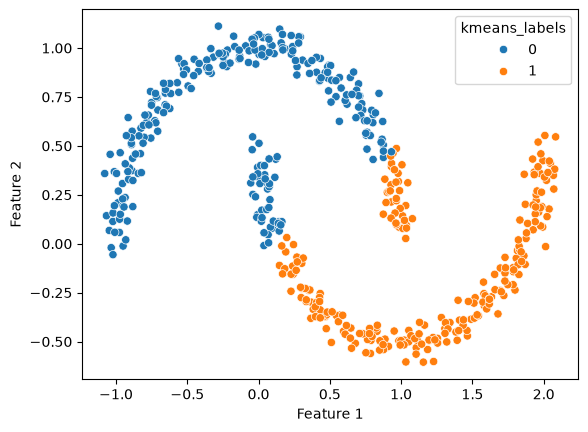

In [27]:
sns.scatterplot(x=df['Feature 1'], y=df['Feature 2'], hue=df['kmeans_labels'], palette='tab10')

In [28]:
dbscan = DBSCAN(eps=0.3, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

In [30]:
df['dbscan_labels'] = dbscan_labels

<Axes: xlabel='Feature 1', ylabel='Feature 2'>

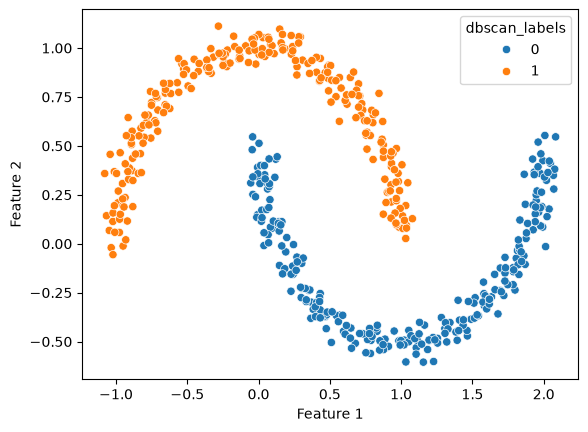

In [31]:
sns.scatterplot(x=df['Feature 1'], y=df['Feature 2'], hue=df['dbscan_labels'], palette='tab10')